# Phân tích khách hàng và sản phẩm trong bán lẻ online

**Môn học:** PSD301M  
**Nhóm thực hiện:** Trí Dũng, Tuấn Triển  
**Dữ liệu:** UCI Online Retail (541,909 dòng, 8 thuộc tính)  
**Công nghệ:** Python · pandas · NumPy · matplotlib

---

## Câu hỏi nghiên cứu chính

> **Nhóm khách hàng và sản phẩm nào tạo ra doanh thu cao, và các đơn hàng có xuất hiện dấu hiệu bất thường hoặc hủy giao dịch hay không?**

**Tám câu hỏi phụ:**
1. Doanh thu biến động theo thời gian như thế nào?
2. Sản phẩm nào được bán với số lượng nhiều nhất?
3. Sản phẩm nào tạo ra doanh thu cao nhất?
4. Phân khúc giá nào có lượng mua cao nhất?
5. Khách hàng nào vừa chi tiêu nhiều vừa mua thường xuyên?
6. Quốc gia nào đóng góp doanh thu nhiều nhất?
7. Khách hàng nào đã lâu không quay lại mua hàng?
8. Sản phẩm nào thường xuyên xuất hiện trong các đơn bị hủy?

---

## Cấu trúc Notebook

| Phần | Nội dung |
|------|----------|
| 1 | Import thư viện & cấu hình |
| 2 | Load dữ liệu & Data Profiling |
| 3 | Data Cleaning |
| 4 | Cấu trúc dữ liệu Python (List, Dict, Set, Tuple) |
| 5 | Phân tích thống kê NumPy & Outlier Detection |
| 6 | Phân khúc khách hàng RFM |
| 7 | EDA — 8 câu hỏi nghiên cứu |
| 8 | Kiểm định chất lượng dữ liệu |


---
## Phần 1 — Import thư viện & cấu hình

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:,.2f}'.format)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (11, 5)

# Notebook nằm trong notebooks/, PROJECT_ROOT là thư mục cha
PROJECT_ROOT  = Path('..').resolve()
RAW_FILE      = PROJECT_ROOT / 'data' / 'raw'       / 'Online_Retail.xlsx'
CLEANED_FILE  = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_retail.csv'
CUSTOMER_FILE = PROJECT_ROOT / 'data' / 'processed' / 'customer_segments.csv'
FIGURES_DIR   = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR    = PROJECT_ROOT / 'reports' / 'tables'

print('Project root   :', PROJECT_ROOT)
print('Raw file exists:', RAW_FILE.exists())
print('Cleaned CSV    :', CLEANED_FILE.exists())

Project root   : D:\Tài liệu kì 5\PDS301m\retail-analytics-project
Raw file exists: True
Cleaned CSV    : True


---
## Phần 2 — Load dữ liệu gốc & Data Profiling

Đọc file Excel gốc và quan sát cấu trúc, chất lượng dữ liệu trước khi làm sạch.

In [2]:
raw = pd.read_excel(RAW_FILE, engine='openpyxl')
print(f'Kich thuoc du lieu goc: {raw.shape[0]:,} dong x {raw.shape[1]} cot')
raw.head(5)

Kich thuoc du lieu goc: 541,909 dong x 8 cot


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


**Nhận xét:** Dataset gốc có **541,909 dòng** và **8 cột**. Mỗi dòng là một dòng sản phẩm trong một hóa đơn.

In [3]:
print('=== Kieu du lieu ===')
print(raw.dtypes)
print()
missing     = raw.isnull().sum()
missing_pct = (missing / len(raw) * 100).round(2)
print('=== Missing values ===')
pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})[missing > 0]

=== Kieu du lieu ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

=== Missing values ===


,Missing Count,Missing %
Description,1454,0.27
CustomerID,135080,24.93


**Nhận xét:**
- `Description` thiếu **1,454 dòng** (~0.3%).
- `CustomerID` thiếu **135,080 dòng** (~24.9%) — giữ lại, chỉ loại khỏi phân tích cấp khách hàng (RFM).

In [4]:
raw[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


In [5]:
duplicates    = raw.duplicated().sum()
neg_quantity  = (raw['Quantity'] < 0).sum()
zero_price    = (raw['UnitPrice'] <= 0).sum()
cancellations = raw['InvoiceNo'].astype(str).str.startswith('C').sum()

pd.DataFrame({
    'Van de': ['Dong trung lap hoan toan', 'Quantity am', 'UnitPrice <= 0', 'Hoa don huy (prefix C)'],
    'So dong': [duplicates, neg_quantity, zero_price, cancellations]
})

,Van de,So dong
0,Dong trung lap hoan toan,5268
1,Quantity am,10624
2,UnitPrice <= 0,2517
3,Hoa don huy (prefix C),9288


**Nhận xét Data Profiling:**
- **5,268 dòng trùng lặp** → loại bỏ để tránh tính 2 lần.
- **10,624 Quantity âm** → phân biệt đơn hủy (giữ lại) và trường hợp khác (loại).
- **UnitPrice ≤ 0** → không phản ánh giao dịch thực → loại bỏ.
- **~9,288 hóa đơn hủy** → giữ lại để phân tích riêng.

---
## Phần 3 — Data Cleaning

Pipeline làm sạch áp dụng theo thứ tự các quy tắc đã thống nhất.

In [6]:
import sys
sys.path.insert(0, str(PROJECT_ROOT))

from src.retail_data_processor import RetailDataProcessor

processor = RetailDataProcessor(RAW_FILE)
processor.load_data()

Loaded: 541,909 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France


In [7]:
df = processor.clean_data()
print(f'Dong ban dau   : 541,909')
print(f'Dong sau clean : {len(df):,}')
print(f'Dong da loai   : {541909 - len(df):,}')
print()
print('Cot moi them vao:', [c for c in df.columns if c not in raw.columns])

After cleaning: 534,129 rows
Dong ban dau   : 541,909
Dong sau clean : 534,129
Dong da loai   : 7,780

Cot moi them vao: ['IsCancelled', 'OrderMonth', 'Revenue']


**Kết quả:** 541,909 → **534,129 dòng** (loại 7,780 dòng). Ba cột mới: `IsCancelled`, `OrderMonth`, `Revenue`.

In [8]:
sales     = df[~df['IsCancelled']].copy()
cancelled = df[df['IsCancelled']].copy()

pd.DataFrame(list({
    'Tong so dong'                : len(df),
    'Dong ban hang binh thuong'   : len(sales),
    'Dong hoa don huy'            : len(cancelled),
    'So hoa don ban hang'         : sales['InvoiceNo'].nunique(),
    'So khach hang xac dinh'      : int(df['CustomerID'].nunique()),
    'So quoc gia'                 : df['Country'].nunique(),
    'So ma san pham (ban hang)'   : sales['StockCode'].nunique(),
    'Dong thieu CustomerID'       : int(df['CustomerID'].isna().sum()),
    'Gross Revenue (ban hang)'    : round(sales['Revenue'].sum(), 0),
    'Gia tri huy'                 : round(cancelled['Revenue'].sum(), 0),
    'Net Revenue'                 : round(df['Revenue'].sum(), 0),
}.items()), columns=['Chi so', 'Gia tri'])

,Chi so,Gia tri
0,Tong so dong,"534,129.00"
1,Dong ban hang binh thuong,"524,878.00"
2,Dong hoa don huy,"9,251.00"
3,So hoa don ban hang,"19,960.00"
4,So khach hang xac dinh,"4,371.00"
5,So quoc gia,38.00
6,So ma san pham (ban hang),"3,922.00"
7,Dong thieu CustomerID,"132,565.00"
8,Gross Revenue (ban hang),"10,642,111.00"
9,Gia tri huy,"-893,980.00"


**Nhận xét:** Giá trị hủy ~−893,980 (~8.4% gross). Net revenue ~9,748,131.

In [9]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,OrderMonth,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,False,2010-12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,2010-12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,False,2010-12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,2010-12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,2010-12,20.34


---
## Phần 4 — Cấu trúc dữ liệu Python

Minh họa 4 cấu trúc dữ liệu cơ bản được dùng trong pipeline.

In [10]:
invoice_records, country_summary, product_codes, date_range = processor.create_basic_structures()

print('=== LIST — invoice_records (2 ban ghi dau) ===')
for rec in invoice_records[:2]:
    print(rec)

=== LIST — invoice_records (2 ban ghi dau) ===
{'InvoiceNo': 536365, 'StockCode': '85123A', 'Description': 'WHITE HANGING HEART T-LIGHT HOLDER', 'Quantity': 6, 'InvoiceDate': Timestamp('2010-12-01 08:26:00'), 'UnitPrice': 2.55, 'CustomerID': 17850.0, 'Country': 'United Kingdom', 'IsCancelled': False, 'OrderMonth': '2010-12', 'Revenue': 15.299999999999999}
{'InvoiceNo': 536365, 'StockCode': 71053, 'Description': 'WHITE METAL LANTERN', 'Quantity': 6, 'InvoiceDate': Timestamp('2010-12-01 08:26:00'), 'UnitPrice': 3.39, 'CustomerID': 17850.0, 'Country': 'United Kingdom', 'IsCancelled': False, 'OrderMonth': '2010-12', 'Revenue': 20.34}


In [11]:
print('=== DICT — country_summary (5 quoc gia dau) ===')
for country, revenue in list(country_summary.items())[:5]:
    print(f'  {country}: {revenue:,.2f}')

=== DICT — country_summary (5 quoc gia dau) ===
  Australia: 138,453.81
  Austria: 10,198.68
  Bahrain: 754.14
  Belgium: 41,196.34
  Brazil: 1,143.60


In [12]:
print('=== SET — product_codes ===')
print(f'  So ma san pham duy nhat: {len(product_codes):,}')
print(f'  Vi du 5 ma: {list(product_codes)[:5]}')

=== SET — product_codes ===
  So ma san pham duy nhat: 3,938
  Vi du 5 ma: ['21932', '35638B', '23191', '20682', '85106']


In [13]:
print('=== TUPLE — date_range ===')
print(f'  Bat dau : {date_range[0]}')
print(f'  Ket thuc: {date_range[1]}')

=== TUPLE — date_range ===
  Bat dau : 2010-12-01 08:26:00
  Ket thuc: 2011-12-09 12:50:00


**Nhận xét:**
- **List** (`invoice_records`): danh sách có thứ tự, hỗ trợ index và vòng lặp.
- **Dict** (`country_summary`): tra cứu theo tên quốc gia O(1).
- **Set** (`product_codes`): đảm bảo không trùng lặp, kiểm tra tồn tại O(1).
- **Tuple** (`date_range`): bất biến — phù hợp lưu metadata không thay đổi.

---
## Phần 5 — Phân tích thống kê NumPy & Outlier Detection

Dùng NumPy tính thống kê mô tả và phát hiện outlier bằng phương pháp IQR:
- `IQR = Q3 − Q1`
- Lower bound = `Q1 − 1.5 × IQR`, Upper bound = `Q3 + 1.5 × IQR`

In [14]:
columns_to_analyze = ['Revenue', 'Quantity', 'UnitPrice']
results = []

for col in columns_to_analyze:
    vals   = sales[col].to_numpy()
    mean   = np.mean(vals)
    median = np.median(vals)
    std    = np.std(vals)
    q1     = np.percentile(vals, 25)
    q3     = np.percentile(vals, 75)
    iqr    = q3 - q1
    lb     = q1 - 1.5 * iqr
    ub     = q3 + 1.5 * iqr
    n_out  = int(((vals < lb) | (vals > ub)).sum())
    results.append({
        'Thuoc tinh': col,
        'Mean': mean, 'Median': median, 'Std': std,
        'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Nguong tren': ub,
        'So outlier': n_out,
        'Ty le %': round(n_out / len(vals) * 100, 2)
    })

pd.DataFrame(results)

,Thuoc tinh,Mean,Median,Std,Q1,Q3,IQR,Nguong tren,So outlier,Ty le %
0,Revenue,20.28,9.92,271.69,3.90,17.70,13.80,38.40,42624,8.12
1,Quantity,10.62,4.00,156.28,1.00,11.00,10.00,26.00,27111,5.17
2,UnitPrice,3.92,2.08,36.09,1.25,4.13,2.88,8.45,37827,7.21


**Nhận xét:**
- **Mean >> Median** ở cả 3 thuộc tính → phân phối lệch phải; một số giao dịch rất lớn kéo mean lên.
- `Revenue`: 42,624 outlier (8.1%). `UnitPrice` outlier lớn thuộc mã phí nội bộ (`AMAZON FEE`, `DOTCOM POSTAGE`).
- Nhóm **giữ lại** outlier — không tự động xóa vì chúng phản ánh nghiệp vụ thực tế.

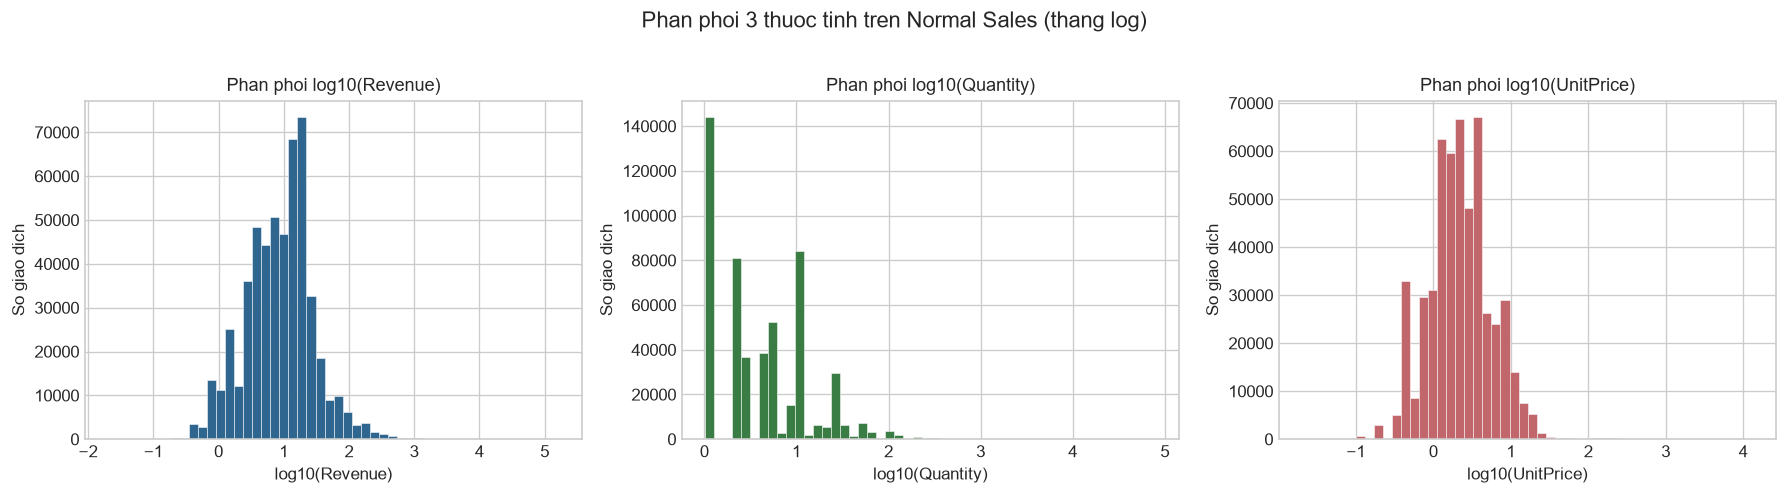

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
attrs = [('Revenue', '#2F6690'), ('Quantity', '#3A7D44'), ('UnitPrice', '#C1666B')]

for ax, (col, color) in zip(axes, attrs):
    vals = sales[col].clip(lower=0.01)
    ax.hist(np.log10(vals + 0.01), bins=50, color=color, edgecolor='white', linewidth=0.3)
    ax.set_title(f'Phan phoi log10({col})', fontsize=11)
    ax.set_xlabel(f'log10({col})')
    ax.set_ylabel('So giao dich')

plt.suptitle('Phan phoi 3 thuoc tinh tren Normal Sales (thang log)', y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'distributions_log.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** Cả ba phân phối đều **lệch phải** — đuôi dài bên phải là bằng chứng trực quan của các giao dịch outlier.

---
## Phần 6 — Phân khúc khách hàng RFM

- **Recency**: số ngày từ lần mua gần nhất đến ngày tham chiếu (thấp = tốt)
- **Frequency**: số hóa đơn bán hàng khác nhau
- **Monetary**: giá trị ròng = `GrossMonetary − CancelledValue`

Điểm R, F, M từ 1–4 (4 là tốt nhất; riêng R ngược lại: Recency thấp → điểm cao).

In [16]:
segments = processor.create_customer_segments()
print(f'So khach hang trong RFM: {len(segments):,}')
segments.head(5)

So khach hang trong RFM: 4,338


,CustomerID,Recency,Frequency,GrossMonetary,CancelledValue,Monetary,R_Score,F_Score,M_Score,Segment
0,"12,346.00",326,1,"77,183.60","77,183.60",0.00,1,1,1,Lost
1,"12,347.00",2,7,"4,310.00",0.00,"4,310.00",4,4,4,Champions
2,"12,348.00",75,4,"1,797.24",0.00,"1,797.24",2,3,4,At Risk
3,"12,349.00",19,1,"1,757.55",0.00,"1,757.55",3,1,4,Regular Customers
4,"12,350.00",310,1,334.40,0.00,334.40,1,1,2,Lost


In [17]:
total_net = segments['Monetary'].sum()
seg_stats = segments.groupby('Segment').agg(
    So_khach=('CustomerID', 'count'),
    Monetary_tong=('Monetary', 'sum'),
    Recency_median=('Recency', 'median'),
    Frequency_median=('Frequency', 'median'),
    Monetary_mean=('Monetary', 'mean')
).round(0)
seg_stats['pct_khach']    = (seg_stats['So_khach'] / seg_stats['So_khach'].sum() * 100).round(1)
seg_stats['pct_doanh_thu'] = (seg_stats['Monetary_tong'] / total_net * 100).round(1)
seg_stats.reindex(['Champions', 'Loyal Customers', 'Regular Customers', 'At Risk', 'Lost'])

,So_khach,Monetary_tong,Recency_median,Frequency_median,Monetary_mean,pct_khach,pct_doanh_thu
Segment,,,,,,,
Champions,1291,"6,229,487.00",15.00,6.00,"4,825.00",29.80,75.20
Loyal Customers,147,"70,684.00",22.00,3.00,481.00,3.40,0.90
Regular Customers,1208,"501,310.00",40.00,1.00,415.00,27.80,6.00
At Risk,862,"1,270,792.00",95.00,3.00,"1,474.00",19.90,15.30
Lost,830,"216,657.00",254.00,1.00,261.00,19.10,2.60


**Nhận xét:**
- **Champions** (29.8% khách trong RFM) → **~75.2% tổng Monetary của 4,338 khách RFM** (tương đương ~63.9% net revenue toàn dataset, sau khi tính cả dòng thiếu CustomerID).
- **At Risk** (19.9%): Recency trung vị 95 ngày, TB 1,474/khách — chiếm ~15.3% Monetary trong RFM; đây là giá trị lịch sử, chưa phải dự báo doanh thu sẽ mất.
- **Lost**: Recency trung vị 254 ngày, chỉ mua 1 lần.
- Khách `12346`: GrossMonetary ≈ CancelledValue ≈ 77,184 → Monetary ròng = 0 → xếp Lost. Chứng minh cần trừ giá trị hủy khi tính Monetary.


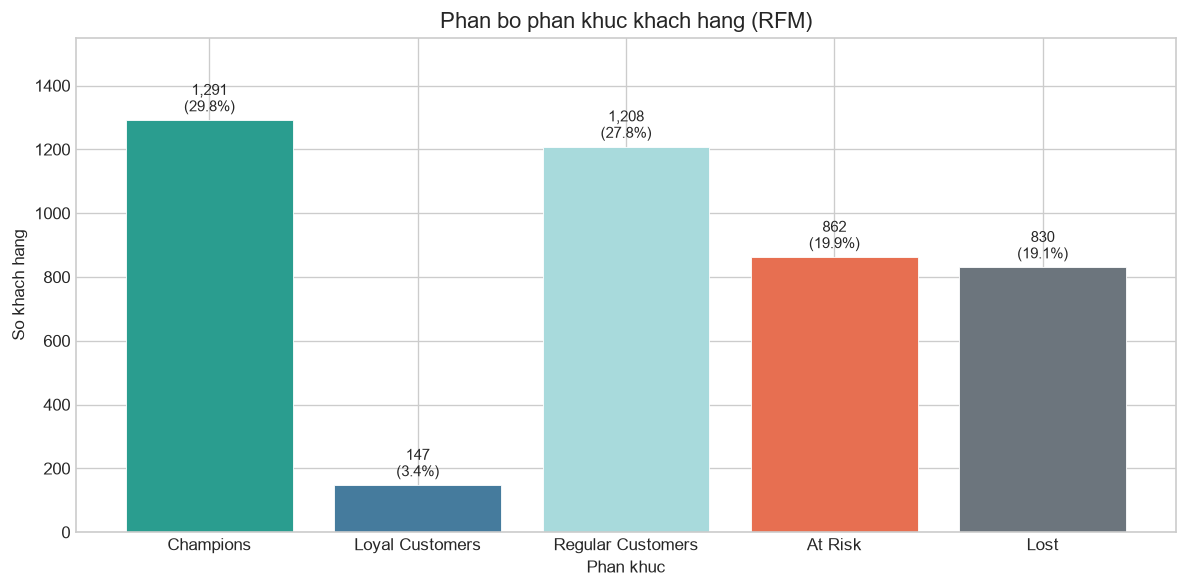

In [18]:
segment_order  = ['Champions', 'Loyal Customers', 'Regular Customers', 'At Risk', 'Lost']
segment_colors = ['#2A9D8F', '#457B9D', '#A8DADC', '#E76F51', '#6C757D']
counts = segments['Segment'].value_counts().reindex(segment_order, fill_value=0)
pcts   = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=segment_colors, edgecolor='white', linewidth=0.5)
for bar, cnt, pct in zip(bars, counts.values, pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
            f'{cnt:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set_title('Phan bo phan khuc khach hang (RFM)', fontsize=13)
ax.set_xlabel('Phan khuc')
ax.set_ylabel('So khach hang')
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'customer_segments_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

In [19]:
top_champ = (
    segments[segments['Segment'] == 'Champions']
    .sort_values('Monetary', ascending=False)
    .head(10)
    [['CustomerID', 'Recency', 'Frequency', 'GrossMonetary', 'CancelledValue', 'Monetary']]
    .reset_index(drop=True)
)
top_champ['CustomerID'] = top_champ['CustomerID'].astype(int)
top_champ

,CustomerID,Recency,Frequency,GrossMonetary,CancelledValue,Monetary
0,14646,2,73,"280,206.02",717.00,"279,489.02"
1,18102,1,60,"259,657.30","3,218.81","256,438.49"
2,17450,8,46,"194,390.79","7,068.62","187,322.17"
3,14911,1,201,"143,711.17","11,252.44","132,458.73"
4,12415,24,21,"124,914.53","1,189.08","123,725.45"
5,14156,10,55,"117,210.08","3,995.49","113,214.59"
6,17511,3,31,"91,062.38","2,937.00","88,125.38"
7,16684,4,28,"66,653.56",761.48,"65,892.08"
8,13694,4,50,"65,039.62","2,349.08","62,690.54"
9,15311,1,91,"60,632.75","1,348.56","59,284.19"


**Nhận xét:** Khách `14646` đứng đầu (279,489 – 73 hóa đơn, Recency 2 ngày). Khách `14911` có **201 hóa đơn** — nổi bật trong bảng 10 khách Monetary cao nhất, nhưng không phải tần suất cao nhất cả nhóm Champions (khách `12748` có 209 hóa đơn, cũng thuộc Champions).


---
## Phần 7 — EDA: Trả lời 8 câu hỏi nghiên cứu

Tất cả phân tích dùng **gross sales** (không bao gồm đơn hủy), ngoại trừ câu hỏi 8.

### Câu hỏi 1 — Doanh thu biến động theo thời gian như thế nào?

In [20]:
monthly_rev = (
    sales.groupby('OrderMonth')['Revenue'].sum()
    .reset_index().sort_values('OrderMonth')
    .rename(columns={'Revenue': 'GrossRevenue'})
)
monthly_rev

,OrderMonth,GrossRevenue
0,2010-12,"821,452.73"
1,2011-01,"689,811.61"
2,2011-02,"522,545.56"
3,2011-03,"716,215.26"
4,2011-04,"536,968.49"
5,2011-05,"769,296.61"
6,2011-06,"760,547.01"
7,2011-07,"718,076.12"
8,2011-08,"757,841.38"
9,2011-09,"1,056,435.19"


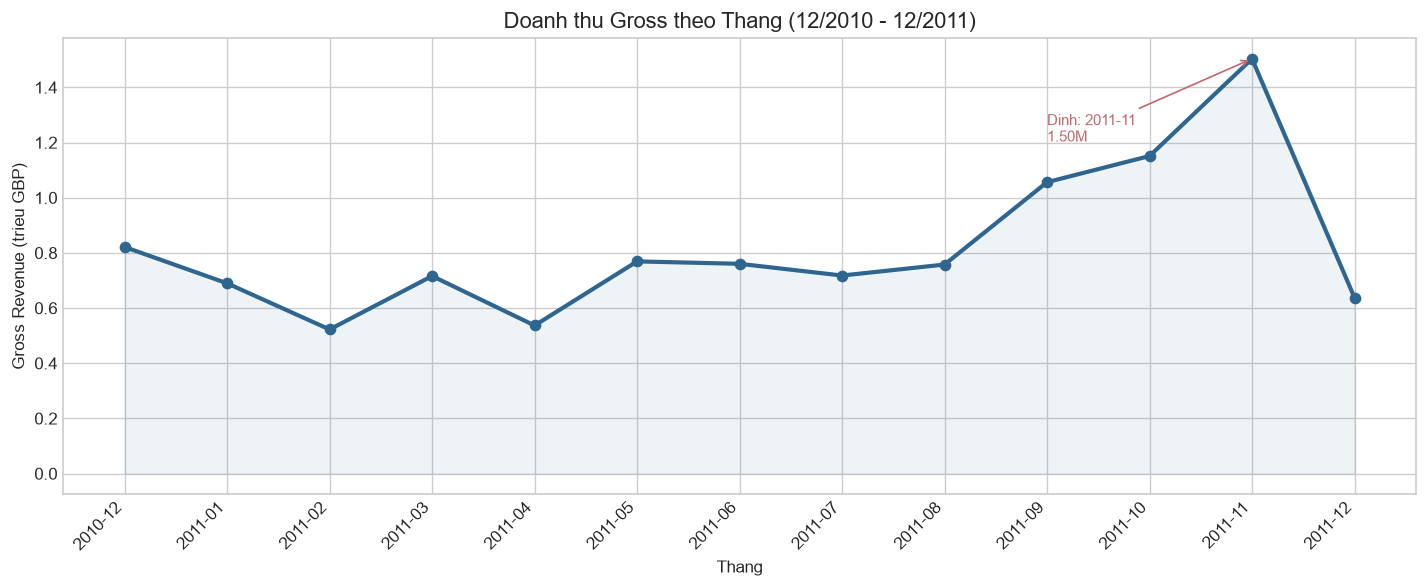

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
x_vals = range(len(monthly_rev))
ax.plot(x_vals, monthly_rev['GrossRevenue'] / 1e6,
        marker='o', linewidth=2.5, markersize=6, color='#2F6690')
ax.fill_between(x_vals, monthly_rev['GrossRevenue'] / 1e6, alpha=0.08, color='#2F6690')

peak_idx = monthly_rev['GrossRevenue'].idxmax()
ax.annotate(
    f'Dinh: {monthly_rev.loc[peak_idx, "OrderMonth"]}\n{monthly_rev.loc[peak_idx, "GrossRevenue"]/1e6:.2f}M',
    xy=(peak_idx, monthly_rev.loc[peak_idx, 'GrossRevenue'] / 1e6),
    xytext=(peak_idx - 2, monthly_rev.loc[peak_idx, 'GrossRevenue'] / 1e6 - 0.3),
    fontsize=9, color='#C1666B',
    arrowprops=dict(arrowstyle='->', color='#C1666B'))

ax.set_xticks(x_vals)
ax.set_xticklabels(monthly_rev['OrderMonth'], rotation=45, ha='right')
ax.set_title('Doanh thu Gross theo Thang (12/2010 - 12/2011)', fontsize=13)
ax.set_xlabel('Thang')
ax.set_ylabel('Gross Revenue (trieu GBP)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'monthly_revenue.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:**
- Doanh thu dao động 0.5–0.8M nửa đầu năm, **tăng mạnh từ tháng 9**.
- **Đỉnh tháng 11/2011: 1.50M** — ba tháng 9, 10, 11 chiếm ~34.9% tổng gross revenue, phù hợp mùa mua sắm cuối năm trước Giáng sinh. (Lưu ý: Q4 lịch dương là tháng 10–12, chiếm ~30.9%; tháng 12 trong dataset chưa đầy đủ.)
- Tháng 12/2011 thấp vì dữ liệu chỉ đến ngày 09/12 — **không phản ánh xu hướng thực**.


### Câu hỏi 2 & 3 — Sản phẩm bán nhiều nhất & doanh thu cao nhất

In [22]:
prod = sales.dropna(subset=['Description']).copy()

top_qty = (
    prod.groupby(['StockCode', 'Description'])['Quantity']
    .sum().sort_values(ascending=False).head(10).reset_index()
)
top_rev = (
    prod.groupby(['StockCode', 'Description'])['Revenue']
    .sum().sort_values(ascending=False).head(10).reset_index()
)

print('Top 10 theo Quantity:')
display(top_qty[['StockCode', 'Description', 'Quantity']])
print('\nTop 10 theo Revenue:')
display(top_rev[['StockCode', 'Description', 'Revenue']])

Top 10 theo Quantity:


,StockCode,Description,Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,85099B,JUMBO BAG RED RETROSPOT,48371
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580
5,22197,POPCORN HOLDER,36749
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
8,23084,RABBIT NIGHT LIGHT,30739
9,22492,MINI PAINT SET VINTAGE,26633



Top 10 theo Revenue:


,StockCode,Description,Revenue
0,DOT,DOTCOM POSTAGE,"206,248.77"
1,22423,REGENCY CAKESTAND 3 TIER,"174,156.54"
2,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60"
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,284.24"
4,47566,PARTY BUNTING,"99,445.23"
5,85099B,JUMBO BAG RED RETROSPOT,"94,159.81"
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92"
7,POST,POSTAGE,"78,101.88"
8,M,Manual,"77,750.27"
9,23084,RABBIT NIGHT LIGHT,"66,870.03"


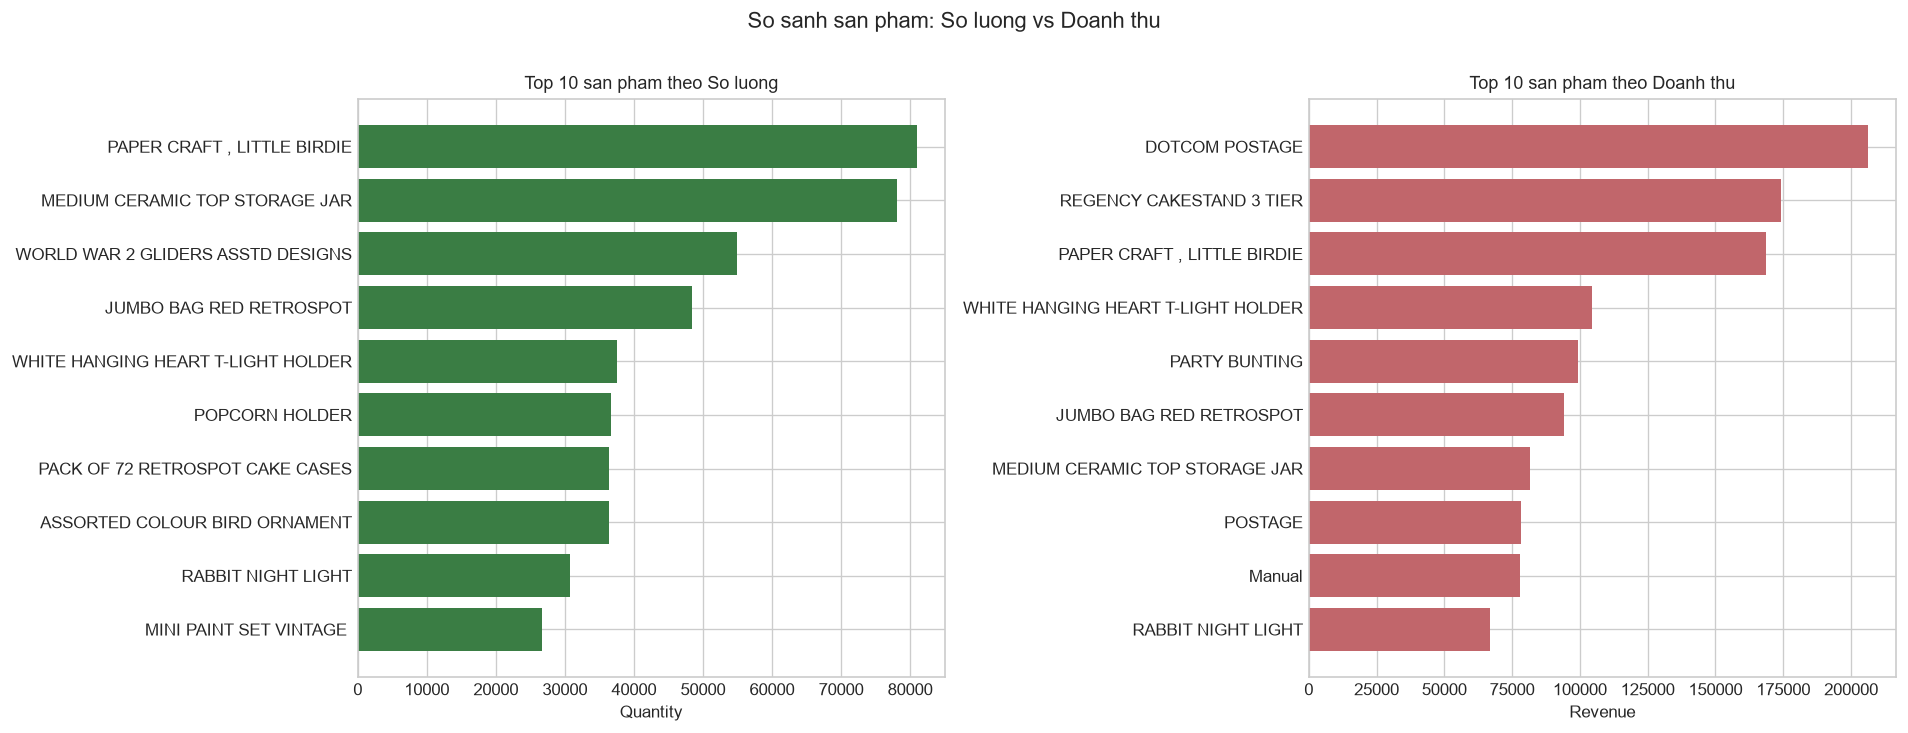

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top_qty.sort_values('Quantity')['Description'],
             top_qty.sort_values('Quantity')['Quantity'], color='#3A7D44')
axes[0].set_title('Top 10 san pham theo So luong', fontsize=11)
axes[0].set_xlabel('Quantity')

axes[1].barh(top_rev.sort_values('Revenue')['Description'],
             top_rev.sort_values('Revenue')['Revenue'], color='#C1666B')
axes[1].set_title('Top 10 san pham theo Doanh thu', fontsize=11)
axes[1].set_xlabel('Revenue')

plt.suptitle('So sanh san pham: So luong vs Doanh thu', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'top_products.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:**
- **Bán nhiều nhất:** *PAPER CRAFT, LITTLE BIRDIE* (80,995) — đơn hàng này bị hủy sau 12 phút.
- **Doanh thu cao nhất:** *DOTCOM POSTAGE* (206,249) là mã phí. Nếu loại → **REGENCY CAKESTAND 3 TIER** đứng đầu (174,157).
- **Kết luận:** sản phẩm bán nhiều ≠ sản phẩm thu nhiều tiền.

### Câu hỏi 4 — Phân khúc giá nào có lượng mua cao nhất?

In [24]:
q1p, medp, q3p = sales['UnitPrice'].quantile([0.25, 0.50, 0.75]).tolist()
print(f'Q1={q1p:.2f} | Median={medp:.2f} | Q3={q3p:.2f}')

sc = sales.copy()
sc['PriceSegment'] = pd.cut(
    sc['UnitPrice'],
    bins=[-np.inf, q1p, medp, q3p, np.inf],
    labels=['Low', 'Medium', 'High', 'Premium'],
    include_lowest=True
)
price_seg = (
    sc.groupby('PriceSegment', observed=True)
    .agg(Quantity=('Quantity', 'sum'), Revenue=('Revenue', 'sum'))
    .reset_index()
)
price_seg

Q1=1.25 | Median=2.08 | Q3=4.13


,PriceSegment,Quantity,Revenue
0,Low,2887471,"2,016,181.78"
1,Medium,1286199,"2,231,863.51"
2,High,897419,"2,585,402.45"
3,Premium,501331,"3,808,663.06"


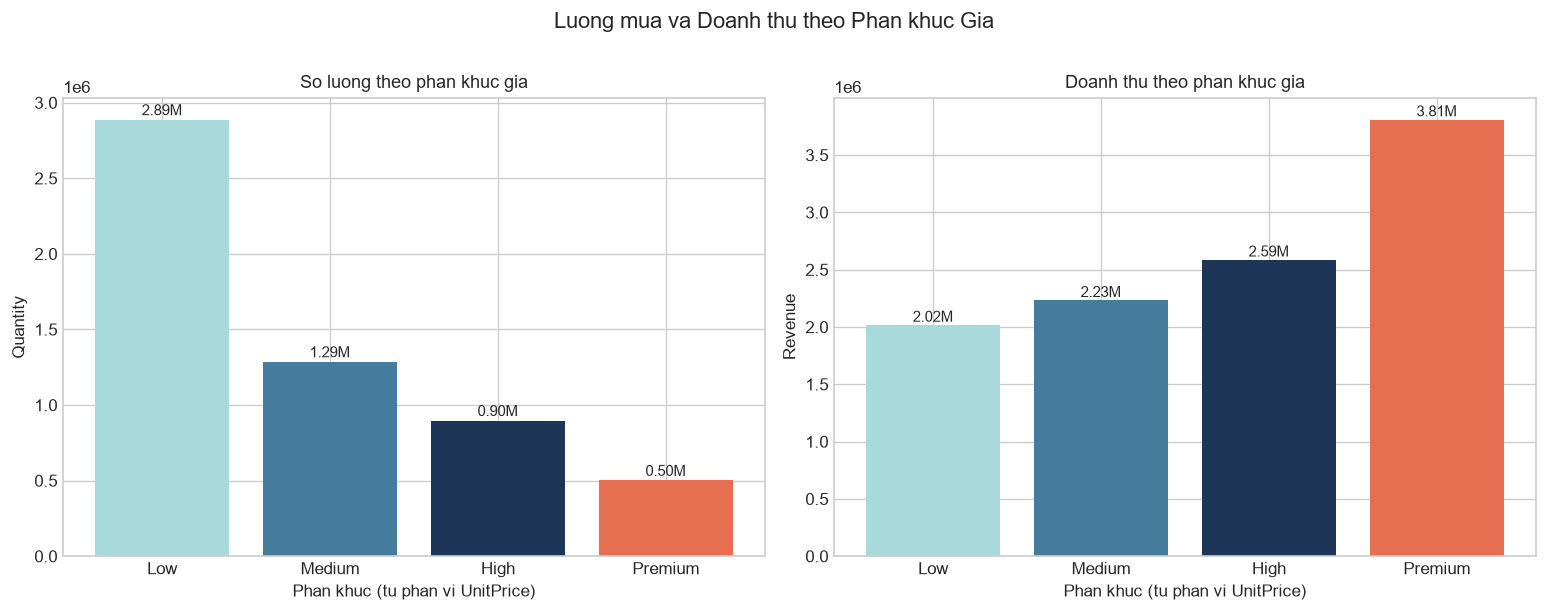

In [25]:
colors = ['#A8DADC', '#457B9D', '#1D3557', '#E76F51']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(price_seg['PriceSegment'].astype(str), price_seg['Quantity'], color=colors)
axes[0].set_title('So luong theo phan khuc gia', fontsize=11)
axes[0].set_xlabel('Phan khuc (tu phan vi UnitPrice)')
axes[0].set_ylabel('Quantity')
for i, v in enumerate(price_seg['Quantity']):
    axes[0].text(i, v + 30000, f'{v/1e6:.2f}M', ha='center', fontsize=9)

axes[1].bar(price_seg['PriceSegment'].astype(str), price_seg['Revenue'], color=colors)
axes[1].set_title('Doanh thu theo phan khuc gia', fontsize=11)
axes[1].set_xlabel('Phan khuc (tu phan vi UnitPrice)')
axes[1].set_ylabel('Revenue')
for i, v in enumerate(price_seg['Revenue']):
    axes[1].text(i, v + 30000, f'{v/1e6:.2f}M', ha='center', fontsize=9)

plt.suptitle('Luong mua va Doanh thu theo Phan khuc Gia', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'price_segments.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** Phân khúc **Low** có lượng mua nhiều nhất (~2.9M). Phân khúc **Premium** tuy bán ít nhất nhưng đóng góp doanh thu cao nhất (~3.8M).

### Câu hỏi 5 — Khách hàng nào vừa chi tiêu nhiều vừa mua thường xuyên?

In [26]:
top_cust = (
    segments[segments['Segment'] == 'Champions']
    .sort_values(['Monetary', 'Frequency'], ascending=False)
    .head(10)
    [['CustomerID', 'Recency', 'Frequency', 'GrossMonetary', 'CancelledValue', 'Monetary']]
    .reset_index(drop=True)
)
top_cust['CustomerID'] = top_cust['CustomerID'].astype(int)
top_cust

,CustomerID,Recency,Frequency,GrossMonetary,CancelledValue,Monetary
0,14646,2,73,"280,206.02",717.00,"279,489.02"
1,18102,1,60,"259,657.30","3,218.81","256,438.49"
2,17450,8,46,"194,390.79","7,068.62","187,322.17"
3,14911,1,201,"143,711.17","11,252.44","132,458.73"
4,12415,24,21,"124,914.53","1,189.08","123,725.45"
5,14156,10,55,"117,210.08","3,995.49","113,214.59"
6,17511,3,31,"91,062.38","2,937.00","88,125.38"
7,16684,4,28,"66,653.56",761.48,"65,892.08"
8,13694,4,50,"65,039.62","2,349.08","62,690.54"
9,15311,1,91,"60,632.75","1,348.56","59,284.19"


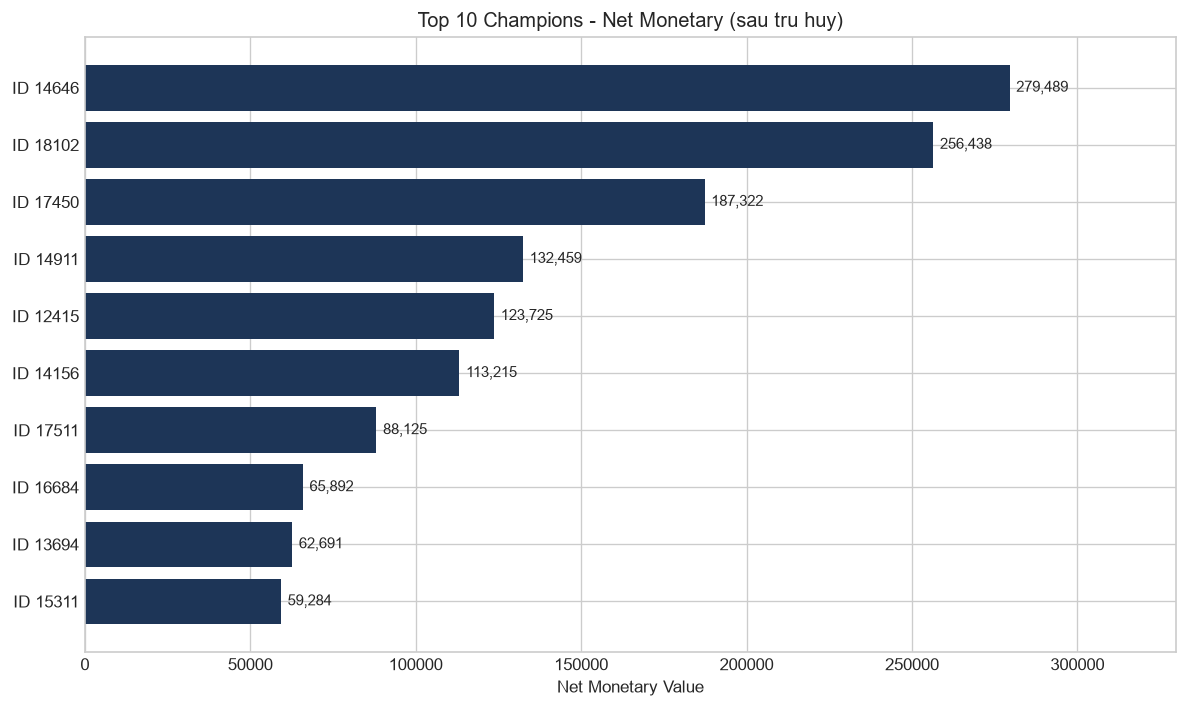

In [27]:
chart_data = top_cust.sort_values('Monetary')
labels = [f'ID {int(x)}' for x in chart_data['CustomerID']]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, chart_data['Monetary'], color='#1D3557')
for bar, val in zip(bars, chart_data['Monetary']):
    ax.text(bar.get_width() + 2000, bar.get_y() + bar.get_height()/2,
            f'{val:,.0f}', va='center', fontsize=9)
ax.set_title('Top 10 Champions - Net Monetary (sau tru huy)', fontsize=12)
ax.set_xlabel('Net Monetary Value')
ax.margins(x=0.18)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'top_customers.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** 3 khách đầu: `14646` (279,489 – 73 hóa đơn), `18102` (256,438 – 60 hóa đơn), `17450` (187,322 – 46 hóa đơn).

### Câu hỏi 6 — Quốc gia nào đóng góp doanh thu nhiều nhất?

In [28]:
country_rev = (
    sales.groupby('Country')['Revenue'].sum()
    .sort_values(ascending=False).head(10).reset_index()
)
uk_pct = country_rev.loc[0, 'Revenue'] / sales['Revenue'].sum() * 100
print(f'United Kingdom chiem {uk_pct:.1f}% tong gross revenue')
country_rev

United Kingdom chiem 84.6% tong gross revenue


,Country,Revenue
0,United Kingdom,"9,001,744.09"
1,Netherlands,"285,446.34"
2,EIRE,"283,140.52"
3,Germany,"228,678.40"
4,France,"209,625.37"
5,Australia,"138,453.81"
6,Spain,"61,558.56"
7,Switzerland,"57,067.60"
8,Belgium,"41,196.34"
9,Sweden,"38,367.83"


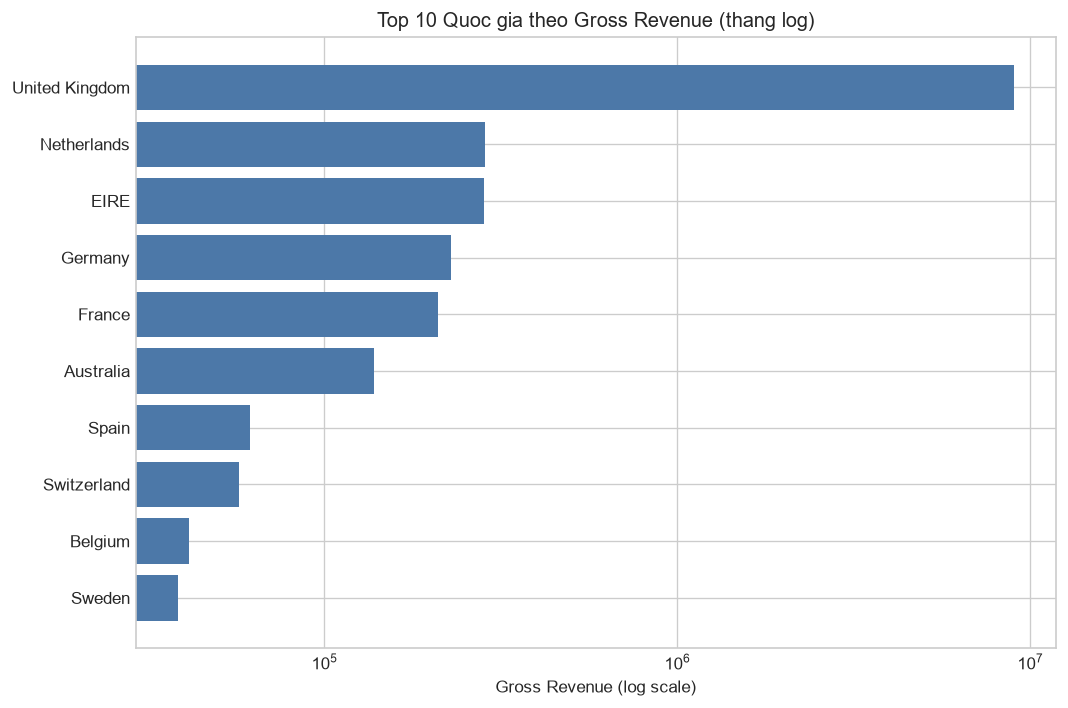

In [29]:
chart = country_rev.sort_values('Revenue')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(chart['Country'], chart['Revenue'], color='#4C78A8')
ax.set_xscale('log')
ax.set_title('Top 10 Quoc gia theo Gross Revenue (thang log)', fontsize=12)
ax.set_xlabel('Gross Revenue (log scale)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'country_revenue.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** UK chiếm ~84.6% gross revenue. Biểu đồ dùng **thang log** vì khoảng cách giữa UK và các nước còn lại quá lớn.

### Câu hỏi 7 — Khách hàng nào đã lâu không quay lại?

In [30]:
inactive = (
    segments[segments['Segment'].isin(['Lost', 'At Risk'])]
    .sort_values(['Recency', 'Monetary'], ascending=[False, False])
    .head(10)
    [['CustomerID', 'Segment', 'Recency', 'Frequency', 'Monetary']]
    .reset_index(drop=True)
)
inactive['CustomerID'] = inactive['CustomerID'].astype(int)
print(f'Tong khach Lost + At Risk: {len(segments[segments["Segment"].isin(["Lost","At Risk"])]):,}')
inactive

Tong khach Lost + At Risk: 1,692


,CustomerID,Segment,Recency,Frequency,Monetary
0,18074,Lost,374,1,489.60
1,14729,Lost,374,1,313.49
2,17968,Lost,374,1,265.10
3,16583,Lost,374,1,233.45
4,17908,Lost,374,1,232.03
5,12791,Lost,374,1,192.60
6,13747,Lost,374,1,79.60
7,15165,Lost,373,1,487.75
8,15922,Lost,373,1,363.60
9,16274,Lost,373,1,351.75


**Nhận xét:** 1,692 khách Lost + At Risk. Recency lớn nhất **374 ngày** — mua từ tháng 12/2010 và không quay lại. Hầu hết mua 1 lần với giá trị nhỏ.

### Câu hỏi 8 — Sản phẩm nào hay xuất hiện trong đơn bị hủy?

In [31]:
cancel_by_invoices = (
    cancelled.dropna(subset=['Description'])
    .groupby(['StockCode', 'Description'])
    .agg(
        So_hoa_don_huy=('InvoiceNo', 'nunique'),
        Quantity_huy=('Quantity', lambda x: x.abs().sum()),
        Gia_tri_huy=('Revenue', lambda x: x.abs().sum())
    )
    .sort_values('So_hoa_don_huy', ascending=False)
    .head(10).reset_index()
)

cancel_by_value = (
    cancelled.dropna(subset=['Description'])
    .groupby(['StockCode', 'Description'])
    .agg(
        So_hoa_don_huy=('InvoiceNo', 'nunique'),
        Quantity_huy=('Quantity', lambda x: x.abs().sum()),
        Gia_tri_huy=('Revenue', lambda x: x.abs().sum())
    )
    .sort_values('Gia_tri_huy', ascending=False)
    .head(10).reset_index()
)

print("Top 10 theo So hoa don huy:")
display(cancel_by_invoices[['StockCode', 'Description', 'So_hoa_don_huy', 'Gia_tri_huy']])
print("\nTop 10 theo Gia tri huy:")
display(cancel_by_value[['StockCode', 'Description', 'So_hoa_don_huy', 'Gia_tri_huy']])


Top 10 theo So hoa don huy:


,StockCode,Description,So_hoa_don_huy,Gia_tri_huy
0,M,Manual,223,"146,784.46"
1,22423,REGENCY CAKESTAND 3 TIER,180,"9,697.05"
2,POST,POSTAGE,124,"11,871.24"
3,22960,JAM MAKING SET WITH JARS,87,"1,012.79"
4,22720,SET OF 3 CAKE TINS PANTRY DESIGN,73,730.10
5,D,Discount,65,"5,696.22"
6,22699,ROSES REGENCY TEACUP AND SAUCER,54,"1,150.35"
7,21232,STRAWBERRY CERAMIC TRINKET BOX,52,414.50
8,22666,RECIPE BOX PANTRY YELLOW DESIGN,47,421.05
9,20725,LUNCH BAG RED RETROSPOT,43,854.70



Top 10 theo Gia tri huy:


,StockCode,Description,So_hoa_don_huy,Gia_tri_huy
0,AMAZONFEE,AMAZON FEE,32,"235,281.59"
1,23843,"PAPER CRAFT , LITTLE BIRDIE",1,"168,469.60"
2,M,Manual,223,"146,784.46"
3,23166,MEDIUM CERAMIC TOP STORAGE JAR,10,"77,479.64"
4,POST,POSTAGE,124,"11,871.24"
5,22423,REGENCY CAKESTAND 3 TIER,180,"9,697.05"
6,CRUK,CRUK Commission,16,"7,933.43"
7,BANK CHARGES,Bank Charges,25,"7,340.64"
8,85123A,WHITE HANGING HEART T-LIGHT HOLDER,42,"6,624.30"
9,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3,"6,591.42"


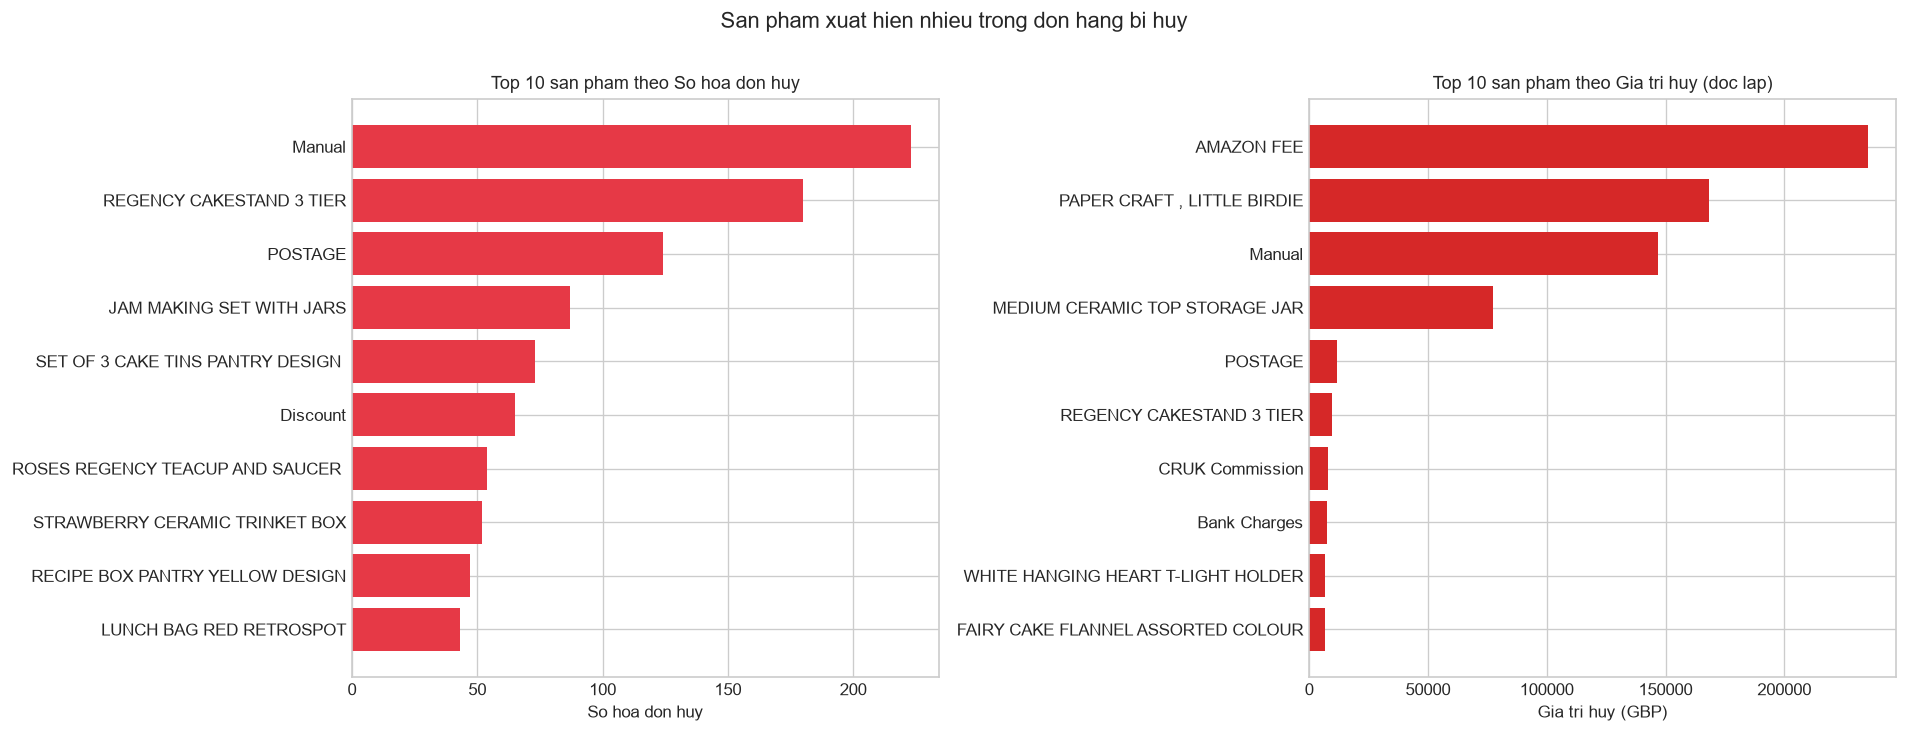

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

c1 = cancel_by_invoices.sort_values('So_hoa_don_huy')
c2 = cancel_by_value.sort_values('Gia_tri_huy')

axes[0].barh(c1['Description'], c1['So_hoa_don_huy'], color='#E63946')
axes[0].set_title('Top 10 san pham theo So hoa don huy', fontsize=11)
axes[0].set_xlabel('So hoa don huy')

axes[1].barh(c2['Description'], c2['Gia_tri_huy'], color='#D62828')
axes[1].set_title('Top 10 san pham theo Gia tri huy (doc lap)', fontsize=11)
axes[1].set_xlabel('Gia tri huy (GBP)')

plt.suptitle('San pham xuat hien nhieu trong don hang bi huy', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cancelled_products.png', dpi=160, bbox_inches='tight')
plt.show()


**Nhận xét:** `Manual` dẫn đầu (223 hóa đơn hủy, 146,784 giá trị). Sản phẩm thật bị hủy nhiều nhất: **REGENCY CAKESTAND 3 TIER** (180 hóa đơn) — cũng là sản phẩm doanh thu cao thứ 2.

### Phân phối giá trị đơn hàng

In [33]:
order_values = sales.groupby('InvoiceNo')['Revenue'].sum()

pd.DataFrame({
    'Thong ke': ['Min', 'Q1', 'Median', 'Mean', 'Q3', 'Max'],
    'Gia tri': [
        order_values.min(), order_values.quantile(0.25),
        order_values.median(), order_values.mean(),
        order_values.quantile(0.75), order_values.max()
    ]
})

,Thong ke,Gia tri
0,Min,0.38
1,Q1,151.70
2,Median,303.30
3,Mean,533.17
4,Q3,493.46
5,Max,"168,469.60"


C:\Users\Admin\AppData\Local\Temp\ipykernel_29424\725185596.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(order_values, vert=False, showfliers=True,


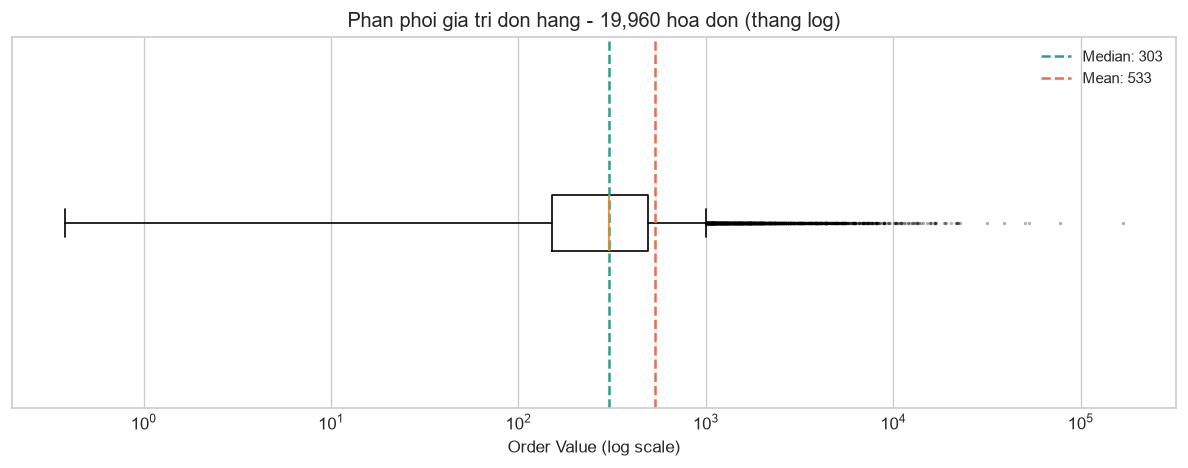

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(order_values, vert=False, showfliers=True,
           flierprops=dict(marker='.', markersize=2, alpha=0.3, color='#E76F51'))
ax.set_xscale('log')
ax.axvline(order_values.median(), color='#2A9D8F', linestyle='--', linewidth=1.5,
           label=f'Median: {order_values.median():,.0f}')
ax.axvline(order_values.mean(), color='#E76F51', linestyle='--', linewidth=1.5,
           label=f'Mean: {order_values.mean():,.0f}')
ax.set_title('Phan phoi gia tri don hang - 19,960 hoa don (thang log)', fontsize=12)
ax.set_xlabel('Order Value (log scale)')
ax.set_yticks([])
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'order_value_boxplot.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** Trung vị 303.30 << Mean 533.17 — phân phối lệch phải. Một số đơn cực lớn (max 168,470) tạo đuôi dài bên phải.

---
## Phần 8 — Kiểm định chất lượng dữ liệu

15 phép kiểm tra tự động chạy trên file đã xuất để xác nhận pipeline không có lỗi.

In [35]:
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

processor.export_results(
    cleaned_file=CLEANED_FILE,
    customer_file=CUSTOMER_FILE,
    customer_segments=segments
)
print('Export hoan tat.')

Exported: D:\Tài liệu kì 5\PDS301m\retail-analytics-project\data\processed\cleaned_retail.csv
Exported: D:\Tài liệu kì 5\PDS301m\retail-analytics-project\data\processed\customer_segments.csv
Export hoan tat.


In [36]:
from src.validation import validate_results

checks = validate_results(CLEANED_FILE, CUSTOMER_FILE)
total_errors = sum(checks.values())
print(f'\nTong so loi: {total_errors}')
if total_errors == 0:
    print('Tat ca 15 kiem tra deu PASS — du lieu dat chat luong.')
else:
    print('Kiem tra FAIL:', {k: v for k, v in checks.items() if v > 0})

Validation results:
- duplicate_rows: 0
- invalid_unit_price: 0
- negative_quantity_not_cancelled: 0
- invalid_cancellation_flag: 0
- wrong_revenue: 0
- wrong_order_month: 0
- missing_customer_id_in_segments: 0
- duplicate_customer_id: 0
- negative_recency: 0
- non_positive_frequency: 0
- invalid_r_score: 0
- invalid_f_score: 0
- invalid_m_score: 0
- inconsistent_frequency_score: 0
- inconsistent_recency_score: 0

Tong so loi: 0
Tat ca 15 kiem tra deu PASS — du lieu dat chat luong.


**Nhận xét:** Cả 15 kiểm tra đều **0 lỗi** — pipeline không có vấn đề chất lượng.

---
## Tổng kết

### Kết quả 8 câu hỏi nghiên cứu

| Câu hỏi | Kết quả |
|---------|----------|
| 1. Doanh thu theo thời gian | Đỉnh tháng 11/2011 (1.50M); Q4 chiếm ~34.9% gross revenue |
| 2. Sản phẩm bán nhiều nhất | *PAPER CRAFT, LITTLE BIRDIE* — 80,995 (đơn bị hủy ngay sau đó) |
| 3. Sản phẩm doanh thu cao nhất | *REGENCY CAKESTAND 3 TIER* nếu loại mã phí — 174,157 |
| 4. Phân khúc giá lượng mua cao | Low (≤ 1.25) — 2.9M; Premium tạo doanh thu cao nhất (3.8M) |
| 5. Khách chi tiêu nhiều & thường xuyên | ID 14646 (279K, 73 hóa đơn); ID 14911 (201 hóa đơn) |
| 6. Quốc gia đóng góp nhiều nhất | United Kingdom — 84.6% gross revenue |
| 7. Khách lâu không quay lại | 1,692 khách Lost+At Risk; Recency max 374 ngày |
| 8. Sản phẩm hay bị hủy | *REGENCY CAKESTAND 3 TIER* — 180 hóa đơn hủy |

### Giới hạn phân tích

1. **Doanh thu là gross** — chưa trừ đơn hủy ở phân tích sản phẩm/tháng/quốc gia.
2. **~25% dòng thiếu CustomerID** → RFM chỉ bao phủ 4,338 khách xác định.
3. **Tháng 12/2011 không đầy đủ** (đến ngày 09/12) → không phản ánh xu hướng thực.
4. **Dữ liệu chỉ ~1 năm** → chưa đủ kết luận chắc chắn về tính mùa vụ.
5. **84.6% doanh thu từ UK** → kết luận chủ yếu phản ánh thị trường Anh.
6. **Mã phí nội bộ** (~3.7% doanh thu) lẫn trong dữ liệu — giữ nguyên và ghi chú.

### Đề xuất hành động

- **Champions:** duy trì loyalty program — nhóm này tạo 75% doanh thu ròng.
- **At Risk:** triển khai win-back campaign trước khi Recency vượt 120 ngày.
- **Mùa vụ Q4:** chuẩn bị tồn kho và marketing từ tháng 8–9.
- **REGENCY CAKESTAND 3 TIER:** điều tra nguyên nhân hủy nhiều (180 hóa đơn) dù doanh thu cao.
